In [1]:
import os, glob
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import fisher_exact
from scipy.stats import mannwhitneyu

In [ ]:
pth = os.path.join('..', '..')
pth_data = os.path.join(pth, 'data')
pth_in = os.path.join(pth_data, 'therapeutic')
pth_feat = os.path.join(pth_data, 'features', 'biomart')
pth_out = os.path.join(pth_data, 'results', 'therapeutic', 'drugs')
pth_fig = os.path.join(pth, 'figures', 'therapeutic', 'drugs')

In [3]:
fn = os.path.join(pth_in, 'minikel_2024_s01.csv')
df = pd.read_csv(fn, sep = '\t')
df = df.loc[df.areas == 'oncology'].copy()

In [4]:
# per-target indications, clinical entry rate
grp = df.groupby('target', observed = True)
n_ind = grp.indication_mesh_id.nunique()
get_clin = lambda s: (s != 'Preclinical').mean()
frac_clin = grp.combined_max_phase.apply(get_clin)

In [ ]:
feat_fn = sorted(glob.glob(os.path.join(pth_feat, '*.csv')))
get_src = lambda fn: os.path.split(fn)[1].replace('.csv', '')
get_feat = lambda fn: pd.read_csv(fn).hsapiens.drop_duplicates()
feat_dict = {get_src(fn) : get_feat(fn) for fn in feat_fn}

# features: targeted, # indications, clinical entry
for src, g in feat_dict.items():
    df_src = g.to_frame()
    df_src['target'] = g.isin(df.target)
    df_src['indications'] = g.map(n_ind.to_dict())
    df_src['clinical'] = g.map(frac_clin.to_dict())
    if src != 'union': feat_dict[src] = df_src.copy()
    else:
        fn = os.path.join(pth_out, 'targets.csv')
        df_src.set_index('hsapiens').to_csv(fn)
del feat_dict['union']

In [6]:
c_dict = {
    'GSE162534'         : plt.cm.tab20c(12),
    'GSE229103'         : plt.cm.tab20c(8),
    'rRNAModifications' : plt.cm.tab20c(4)}

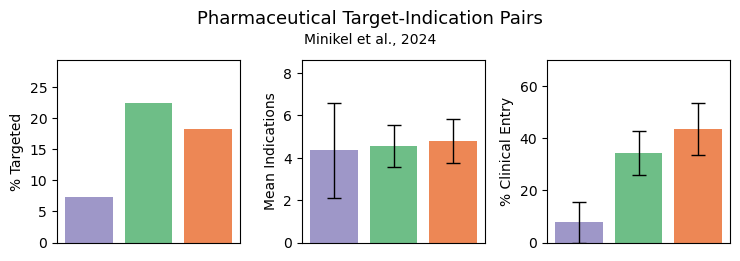

In [ ]:
# plot metrics
fig, ax = plt.subplots(1, 3, figsize = (7.5, 2.5))
for i, (src, df_src) in enumerate(feat_dict.items()):
    tgt = df_src.target.copy()
    df_tgt = df_src.loc[tgt].copy()
    ind = df_tgt.indications.copy()
    clin = df_tgt.clinical.copy() * 100
    c, a = c_dict[src], .7

    # bar plots
    ax[0].bar(i, tgt.mean() * 100, color = c, alpha = a)
    ax[1].bar(i, ind.mean(), yerr = ind.sem(), color = c,
              alpha = a, capsize = 5, error_kw = {'lw' : 1})
    ax[2].bar(i, clin.mean(), yerr = clin.sem(), color = c,
              alpha = a, capsize = 5, error_kw = {'lw' : 1})

for i in range(3):
    ax[i].set_xticks([])
    ax[i].set_box_aspect(1)
    _, ymax = ax[i].get_ylim()
    ymax *= 1.25
    ax[i].set_ylim(top = ymax)

fig.suptitle('Pharmaceutical Target-Indication Pairs',
             size = 13, y = 1.)
fig.text(.5, .865, 'Minikel et al., 2024', ha = 'center')
ax[0].set_ylabel('% Targeted')
ax[1].set_ylabel('Mean Indications')
ax[2].set_ylabel('% Clinical Entry')

fig.tight_layout()
fn = os.path.join(pth_fig, 'targets.pdf')
plt.savefig(fn, bbox_inches = 'tight')

In [8]:
# statistical tests
for src0, src1, alt in (
    ('GSE162534', 'GSE229103', 'greater'),
    ('GSE162534', 'rRNAModifications', 'greater'),
    ('GSE229103', 'rRNAModifications', 'two-sided')):

    df_src0 = feat_dict[src0].copy()
    df_src1 = feat_dict[src1].copy()
    tgt0 = df_src0.target.copy()
    tgt1 = df_src1.target.copy()
    df_tgt0 = df_src0.loc[tgt0].copy()
    df_tgt1 = df_src1.loc[tgt1].copy()
    ind0 = df_tgt0.indications.copy()
    ind1 = df_tgt1.indications.copy()
    clin0 = df_tgt0.clinical.copy()
    clin1 = df_tgt1.clinical.copy()
    tab = pd.concat((tgt0.value_counts(),
        tgt1.value_counts()), axis = 1)

    print('\n', src0, src1)
    print('Targets:', fisher_exact(tab, alternative = alt))
    print('Indications:', mannwhitneyu(ind0, ind1))
    print('Entry:', mannwhitneyu(clin1, clin0, alternative = alt))


 GSE162534 GSE229103
Targets: SignificanceResult(statistic=np.float64(3.6184210526315788), pvalue=np.float64(0.004500257394104088))
Indications: MannwhitneyuResult(statistic=np.float64(57.0), pvalue=np.float64(0.6242917704861392))
Entry: MannwhitneyuResult(statistic=np.float64(91.0), pvalue=np.float64(0.064032966409866))

 GSE162534 rRNAModifications
Targets: SignificanceResult(statistic=np.float64(2.7941176470588234), pvalue=np.float64(0.024950427224935217))
Indications: MannwhitneyuResult(statistic=np.float64(46.0), pvalue=np.float64(0.492530777820975))
Entry: MannwhitneyuResult(statistic=np.float64(82.5), pvalue=np.float64(0.039770038410053075))

 GSE229103 rRNAModifications
Targets: SignificanceResult(statistic=np.float64(0.772192513368984), pvalue=np.float64(0.48812058794450053))
Indications: MannwhitneyuResult(statistic=np.float64(192.5), pvalue=np.float64(0.6693444951097682))
Entry: MannwhitneyuResult(statistic=np.float64(229.5), pvalue=np.float64(0.5773600657925428))
